In [1]:
# configuration et chargement
import os, json, copy, random, itertools, time
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
import glob
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, classification_report)
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA = glob.glob("/kaggle/input/**/prep_data.pt", recursive=True)[0]
print(DATA)
OUT_DIR = "/kaggle/working/results"; os.makedirs(OUT_DIR, exist_ok=True)

d = torch.load(DATA, weights_only=False)      # le fichier contient des tableaux numpy et des listes
X, y = d["X"], d["y_cls"].long()
tr, va, te = [np.asarray(d[k]) for k in ("train", "val", "test")]
itos, MAX_LEN = d["itos"], d["max_len"]
VOCAB, N_CLASSES = len(itos), 3
CLASS_NAMES = ["faible", "moyen", "élevé"]
print("device :", DEVICE, "| X :", tuple(X.shape), "| vocabulaire :", VOCAB, "| token_col :", d["token_col"])
print("train / val / test :", len(tr), len(va), len(te))

/kaggle/input/datasets/lorraineagns/prep-data-arabic/prep_data.pt
device : cuda | X : (570, 256) | vocabulaire : 7762 | token_col : lemmas
train / val / test : 399 85 86


In [2]:
# dataloaders et pondération des classes (classes déséquilibrées : 337 / 118 / 115)
def loader(idx, bs, shuffle):
    return DataLoader(TensorDataset(X[idx], y[idx]), batch_size=bs, shuffle=shuffle)

BS = 32
train_loader, val_loader, test_loader = loader(tr, BS, True), loader(va, BS, False), loader(te, BS, False)

counts = np.bincount(y[tr].numpy(), minlength=N_CLASSES)
class_w = torch.tensor(len(tr) / (N_CLASSES * counts), dtype=torch.float32).to(DEVICE)
print("effectifs train :", counts, "| poids de classes :", class_w.cpu().numpy().round(2))

effectifs train : [236  83  80] | poids de classes : [0.56 1.6  1.66]


In [4]:
# modèle générique : RNN / BiRNN / GRU / LSTM
class SeqClassifier(nn.Module):
    def __init__(self, kind, vocab, emb=128, hidden=128, layers=1, dropout=0.4, n_classes=3):
        super().__init__()
        self.bidir = kind == "BiRNN"
        cell = {"RNN": nn.RNN, "BiRNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[kind]
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        self.rnn = cell(emb, hidden, num_layers=layers, batch_first=True, bidirectional=self.bidir,
                        dropout=dropout if layers > 1 else 0.0)
        self.fc = nn.Linear(hidden * (2 if self.bidir else 1), n_classes)
        self.is_lstm = kind == "LSTM"

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()          # longueurs réelles (hors padding)
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        h = h[0] if self.is_lstm else h                         # (layers*dirs, B, H)
        last = torch.cat([h[-2], h[-1]], dim=1) if self.bidir else h[-1]
        return self.fc(self.drop(last))

In [6]:
# entraînement avec early stopping sur le F1 macro de validation
def predict(model, dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for xb, yb in dl:
            ps.append(model(xb.to(DEVICE)).argmax(1).cpu()); ys.append(yb)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

def fit(kind, hp, seed=SEED, epochs=40, patience=8, verbose=False):
    set_seed(seed)
    model = SeqClassifier(kind, VOCAB, hp["emb"], hp["hidden"], hp["layers"], hp["dropout"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp.get("wd", 1e-5))
    lossf = nn.CrossEntropyLoss(weight=class_w)
    best_f1, best_state, wait, hist = -1, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = lossf(model(xb), yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # évite l'explosion du gradient (RNN simple)
            opt.step(); tot += loss.item() * len(xb)
        yv, pv = predict(model, val_loader)
        f1 = f1_score(yv, pv, average="macro", zero_division=0)
        hist.append((tot / len(tr), f1))
        if verbose: print(f"ep {ep:02d} loss {tot/len(tr):.4f} val F1 {f1:.3f}")
        if f1 > best_f1: best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    return model, best_f1, hist

In [7]:
# recherche d'hyperparamètres (grille réduite) sur la validation
GRID = {"hidden": [64, 128], "dropout": [0.3, 0.5], "lr": [1e-3, 3e-3]}
FIXED = {"emb": 128, "layers": 1}
KINDS = ["RNN", "BiRNN", "GRU", "LSTM"]

rows, best_hp = [], {}
t0 = time.time()
for kind in KINDS:
    for h, dr, lr in itertools.product(GRID["hidden"], GRID["dropout"], GRID["lr"]):
        hp = {**FIXED, "hidden": h, "dropout": dr, "lr": lr}
        _, f1, _ = fit(kind, hp)
        rows.append({"modèle": kind, **hp, "val_F1_macro": round(f1, 4)})
    print(f"{kind} terminé ({time.time()-t0:.0f}s)")

grid_df = pd.DataFrame(rows)
for kind in KINDS:
    best_hp[kind] = grid_df[grid_df["modèle"] == kind].sort_values("val_F1_macro", ascending=False).iloc[0][
        ["emb", "hidden", "layers", "dropout", "lr"]].to_dict()
    best_hp[kind].update(emb=int(best_hp[kind]["emb"]), hidden=int(best_hp[kind]["hidden"]), layers=int(best_hp[kind]["layers"]))
grid_df.to_csv(f"{OUT_DIR}/grid_search.csv", index=False)
display(grid_df.sort_values(["modèle", "val_F1_macro"], ascending=[True, False]))
print(json.dumps(best_hp, indent=1, default=float))

RNN terminé (28s)
BiRNN terminé (69s)
GRU terminé (109s)
LSTM terminé (141s)


,modèle,emb,layers,hidden,dropout,lr,val_F1_macro
14,BiRNN,128,1,128,0.5,0.001,0.5837
12,BiRNN,128,1,128,0.3,0.001,0.5644
15,BiRNN,128,1,128,0.5,0.003,0.4785
10,BiRNN,128,1,64,0.5,0.001,0.4676
9,BiRNN,128,1,64,0.3,0.003,0.4599
11,BiRNN,128,1,64,0.5,0.003,0.4549
8,BiRNN,128,1,64,0.3,0.001,0.4523
13,BiRNN,128,1,128,0.3,0.003,0.4471
23,GRU,128,1,128,0.5,0.003,0.5902
19,GRU,128,1,64,0.5,0.003,0.5834


{
 "RNN": {
  "emb": 128,
  "hidden": 64,
  "layers": 1,
  "dropout": 0.3,
  "lr": 0.003
 },
 "BiRNN": {
  "emb": 128,
  "hidden": 128,
  "layers": 1,
  "dropout": 0.5,
  "lr": 0.001
 },
 "GRU": {
  "emb": 128,
  "hidden": 128,
  "layers": 1,
  "dropout": 0.5,
  "lr": 0.003
 },
 "LSTM": {
  "emb": 128,
  "hidden": 64,
  "layers": 1,
  "dropout": 0.3,
  "lr": 0.003
 }
}


In [12]:
# Notebook : 03_rnn_gru_lstm.ipynb  (cellule 5 corrigée)
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef
SEEDS = [42, 7, 123]
results, preds, histories = [], {}, {}
for kind in KINDS:
    m = {k: [] for k in ["acc", "p", "r", "f1", "bacc", "kappa", "mcc", "time", "vf1"]}
    runs = []
    for s in SEEDS:
        t0 = time.time()
        model, vf1, hist = fit(kind, best_hp[kind], seed=s)
        m["time"].append(time.time() - t0); m["vf1"].append(vf1)
        yt, yp = predict(model, test_loader)
        p, r, f, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
        m["acc"].append(accuracy_score(yt, yp)); m["p"].append(p); m["r"].append(r); m["f1"].append(f)
        m["bacc"].append(balanced_accuracy_score(yt, yp)); m["kappa"].append(cohen_kappa_score(yt, yp))
        m["mcc"].append(matthews_corrcoef(yt, yp)); runs.append((yt, yp, hist))
    n_params = sum(p.numel() for p in model.parameters())
    preds[kind] = (np.concatenate([r_[0] for r_ in runs]), np.concatenate([r_[1] for r_ in runs]))  # 3 exécutions cumulées
    histories[kind] = runs[int(np.argmax(m["vf1"]))][2]          # courbe : exécution choisie sur la VALIDATION
    results.append({"modèle": kind, "accuracy": np.mean(m["acc"]), "précision (macro)": np.mean(m["p"]),
                    "rappel (macro)": np.mean(m["r"]), "F1 (macro)": np.mean(m["f1"]), "± F1": np.std(m["f1"]),
                    "acc. équilibrée": np.mean(m["bacc"]), "kappa": np.mean(m["kappa"]), "MCC": np.mean(m["mcc"]),
                    "temps (s)": np.mean(m["time"]), "paramètres": n_params})
res_df = pd.DataFrame(results).round(4)
res_df.to_csv(f"{OUT_DIR}/test_metrics.csv", index=False)
display(res_df)

,modèle,accuracy,précision (macro),rappel (macro),F1 (macro),± F1,acc. équilibrée,kappa,MCC,temps (s),paramètres
0,RNN,0.4729,0.3940,0.3744,0.3771,0.0660,0.3744,0.0891,0.0917,2.8735,1006147
1,BiRNN,0.6705,0.5563,0.5091,0.5066,0.0372,0.5091,0.3429,0.3715,7.2378,1060355
2,GRU,0.7171,0.5894,0.5635,0.5653,0.0318,0.5635,0.4594,0.4714,5.2187,1092995
3,LSTM,0.6783,0.5280,0.5258,0.5207,0.0368,0.5258,0.3817,0.3943,4.3542,1043395


In [13]:
# BLEU (voir remarque dans le rapport : métrique de génération, ici appliquée à la séquence des labels prédits)
sm = SmoothingFunction().method1
bleu_rows = []
for kind in KINDS:
    yt, yp = preds[kind]
    ref, hyp = [[str(v) for v in yt]], [str(v) for v in yp]
    bleu_rows.append({"modèle": kind,
                      "BLEU-1": corpus_bleu([ref], [hyp], weights=(1, 0, 0, 0), smoothing_function=sm),
                      "BLEU-2": corpus_bleu([ref], [hyp], weights=(.5, .5, 0, 0), smoothing_function=sm)})
bleu_df = pd.DataFrame(bleu_rows).round(4)
bleu_df.to_csv(f"{OUT_DIR}/bleu.csv", index=False)
display(bleu_df)

,modèle,BLEU-1,BLEU-2
0,RNN,0.9612,0.9133
1,BiRNN,0.8333,0.7745
2,GRU,0.8915,0.8474
3,LSTM,0.8837,0.8416


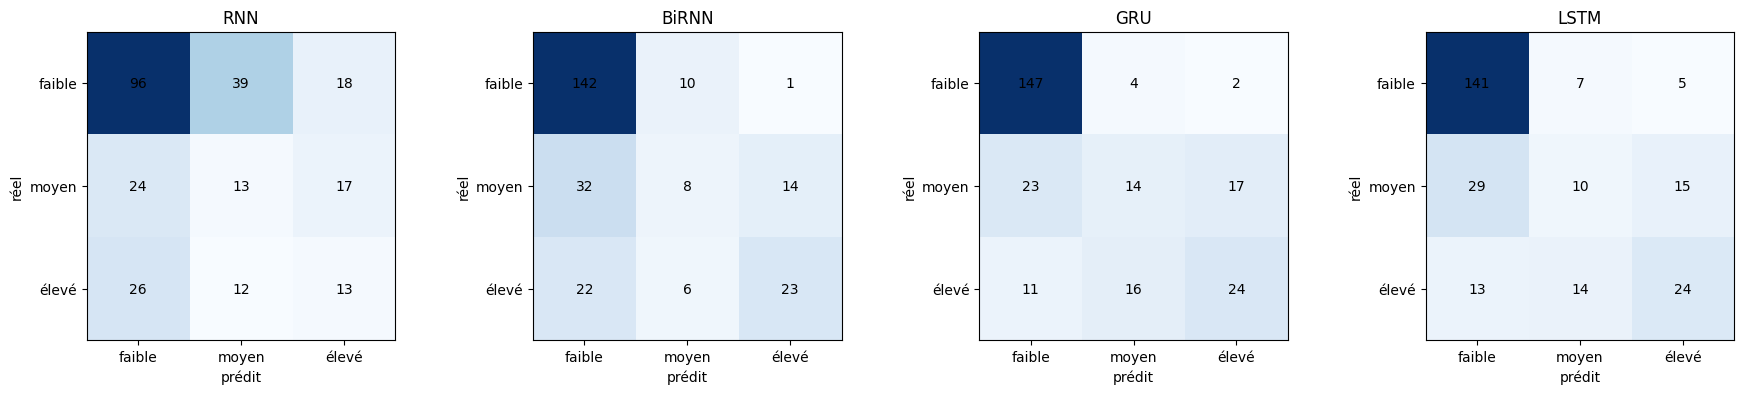


=== RNN ===
              precision    recall  f1-score   support

      faible       0.66      0.63      0.64       153
       moyen       0.20      0.24      0.22        54
       élevé       0.27      0.25      0.26        51

    accuracy                           0.47       258
   macro avg       0.38      0.37      0.38       258
weighted avg       0.49      0.47      0.48       258


=== BiRNN ===
              precision    recall  f1-score   support

      faible       0.72      0.93      0.81       153
       moyen       0.33      0.15      0.21        54
       élevé       0.61      0.45      0.52        51

    accuracy                           0.67       258
   macro avg       0.55      0.51      0.51       258
weighted avg       0.62      0.67      0.63       258


=== GRU ===
              precision    recall  f1-score   support

      faible       0.81      0.96      0.88       153
       moyen       0.41      0.26      0.32        54
       élevé       0.56      0.47 

In [14]:
# matrices de confusion et rapports par classe
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, kind in zip(axs, KINDS):
    yt, yp = preds[kind]
    cm = confusion_matrix(yt, yp, labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues"); ax.set_title(kind)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("prédit"); ax.set_ylabel("réel")
    for i in range(3):
        for j in range(3): ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150); plt.show()

for kind in KINDS:
    print(f"\n=== {kind} ===")
    print(classification_report(*preds[kind], target_names=CLASS_NAMES, zero_division=0))

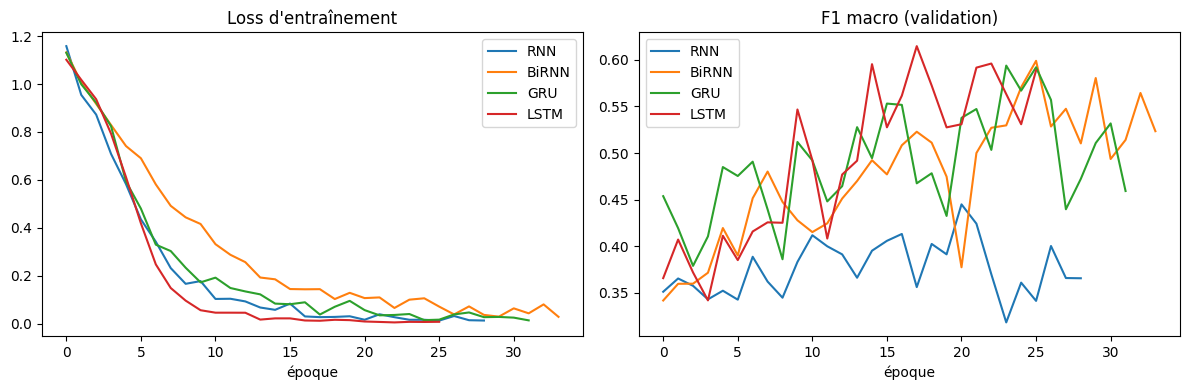

In [15]:
# courbes d'apprentissage (loss d'entraînement et F1 de validation)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for kind in KINDS:
    axs[0].plot([h[0] for h in histories[kind]], label=kind)
    axs[1].plot([h[1] for h in histories[kind]], label=kind)
axs[0].set_title("Loss d'entraînement"); axs[1].set_title("F1 macro (validation)")
for a in axs: a.set_xlabel("époque"); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learning_curves.png", dpi=150); plt.show()

In [16]:
#  repères de comparaison
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

def bow(idx):
    ids = X[idx].numpy()
    rows = np.repeat(np.arange(len(idx)), ids.shape[1])
    m = csr_matrix((np.ones(ids.size), (rows, ids.ravel())), shape=(len(idx), VOCAB))
    return m[:, 2:]                                   # retire <pad> et <unk>

Xtr_b, Xte_b = bow(tr), bow(te)
tfidf = TfidfTransformer(sublinear_tf=True).fit(Xtr_b)
ytr_, yte_ = y[tr].numpy(), y[te].numpy()
for name, clf, A, B in [
    ("Toujours 'faible'", DummyClassifier(strategy="most_frequent"), Xtr_b, Xte_b),
    ("TF-IDF + régression logistique", LogisticRegression(class_weight="balanced", C=10, max_iter=3000),
     tfidf.transform(Xtr_b), tfidf.transform(Xte_b))]:
    p = clf.fit(A, ytr_).predict(B)
    print(f"{name:32s} accuracy {accuracy_score(yte_, p):.3f} | F1 macro {f1_score(yte_, p, average='macro', zero_division=0):.3f}")

Toujours 'faible'                accuracy 0.593 | F1 macro 0.248
TF-IDF + régression logistique   accuracy 0.826 | F1 macro 0.741
